*Commentary pending: intro.*

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.decomposition import PCA

sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from voteview import load_members

warnings.filterwarnings("ignore")
COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
OUTPUTS = Path.cwd().parent / "outputs"
MIN_VOTES = 50
states = pd.read_parquet(OUTPUTS / "gru_member_states.parquet")
states = states[states["votes"] >= MIN_VOTES]
hidden = [c for c in states.columns if c.startswith("h") and c[1:].isdigit()]
members = load_members()[["congress", "chamber", "icpsr", "nokken_poole_dim1", "nominate_dim1"]].drop_duplicates(["congress", "chamber", "icpsr"])
states = states.merge(members, on=["congress", "chamber", "icpsr"], how="left")
# Same-Congress Nokken-Poole distance toward the other party, measured from the party median. Descriptive only.
median = states.groupby(["congress", "chamber", "party"])["nokken_poole_dim1"].transform("median")
states["np_toward_other"] = (states["nokken_poole_dim1"] - median) * np.where(states["party"] == "D", 1, -1)
states["np_extremity"] = states["nokken_poole_dim1"].abs()
states["year"] = 1789 + 2 * (states["congress"] - 1)
print(f"{len(states):,} member-Congresses with at least {MIN_VOTES} party-opposed votes, Congresses {states['congress'].min()} to {states['congress'].max()}")
print("mean_p_gru: the GRU's average predicted defection probability over a member's party-opposed votes in that Congress,")
print("each prediction made from earlier votes only. Congresses 102 to 111 are training years, so those values are in-sample.")


11,855 member-Congresses with at least 50 party-opposed votes, Congresses 97 to 118
mean_p_gru: the GRU's average predicted defection probability over a member's party-opposed votes in that Congress,
each prediction made from earlier votes only. Congresses 102 to 111 are training years, so those values are in-sample.


## Does the learned propensity track moderation?

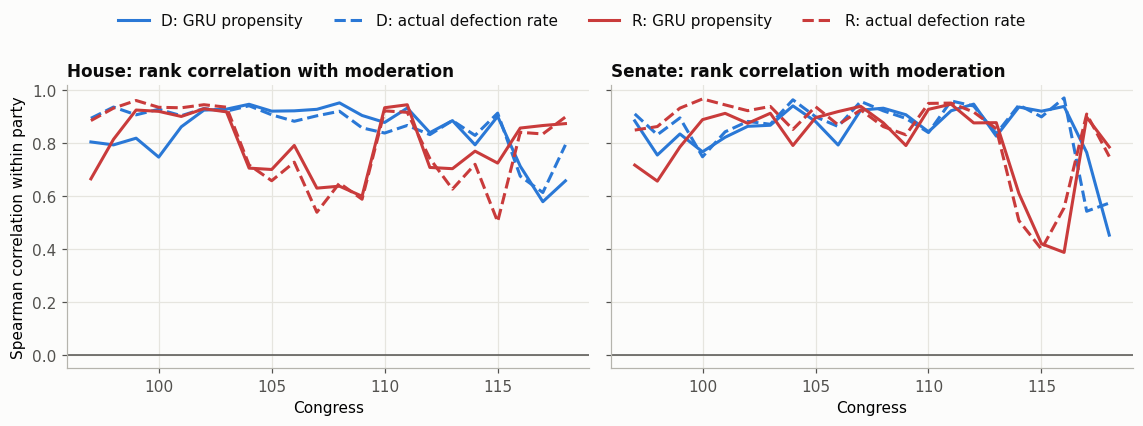

Mean within-party rank correlations by period:


GRU propensity vs Nokken-Poole toward other party  \
chamber party period                                                                        
House   D     1981-1990 (history only)                                              0.804   
              1991-2010 (train)                                                     0.922   
              2011-2014 (validation)                                                0.861   
              2015-2024 (test)                                                      0.728   
        R     1981-1990 (history only)                                              0.844   
              1991-2010 (train)                                                     0.778   
              2011-2014 (validation)                                                0.705   
              2015-2024 (test)                                                      0.817   
Senate  D     1981-1990 (history only)                                              0.811   
              1991-2010 (train)                                                     0.886   
              2011-2014 (validation)                                                0.885   
              2015-2024 (test)                                                      0.801   
        R     1981-1990 (history only)                                              0.791   
              1991-2010 (train)                                                     0.886   
              2011-2014 (validation)                                                0.875   
              2015-2024 (test)                                                      0.620   

                                        actual defection vs Nokken-Poole toward other party  \
chamber party period                                                                          
House   D     1981-1990 (history only)                                              0.912     
              1991-2010 (train)                                                     0.895     
              2011-2014 (validation)                                                0.857     
              2015-2024 (test)                                                      0.764     
        R     1981-1990 (history only)                                              0.928     
              1991-2010 (train)                                                     0.759     
              2011-2014 (validation)                                                0.683     
              2015-2024 (test)                                                      0.759     
Senate  D     1981-1990 (history only)                                              0.844     
              1991-2010 (train)                                                     0.904     
              2011-2014 (validation)                                                0.886     
              2015-2024 (test)                                                      0.785     
        R     1981-1990 (history only)                                              0.910     
              1991-2010 (train)                                                     0.903     
              2011-2014 (validation)                                                0.884     
              2015-2024 (test)                                                      0.624     

                                        GRU propensity vs actual defection  
chamber party period                                                        
House   D     1981-1990 (history only)                               0.892  
              1991-2010 (train)                                      0.959  
              2011-2014 (validation)                                 0.935  
              2015-2024 (test)                                       0.889  
        R     1981-1990 (history only)                               0.927  
              1991-2010 (train)                                      0.933  
              2011-2014 (validation)  

In [2]:
rows = []
for (congress, chamber, party), group in states.groupby(["congress", "chamber", "party"]):
    if len(group) < 15:
        continue
    rows.append({"congress": congress, "chamber": chamber, "party": party, "members": len(group),
                 "GRU propensity vs Nokken-Poole toward other party": spearmanr(group["mean_p_gru"], group["np_toward_other"]).statistic,
                 "actual defection vs Nokken-Poole toward other party": spearmanr(group["defection_rate"], group["np_toward_other"]).statistic,
                 "GRU propensity vs actual defection": spearmanr(group["mean_p_gru"], group["defection_rate"]).statistic})
corr = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
for axis, chamber in zip(axes, ["House", "Senate"]):
    for party in ["D", "R"]:
        part = corr[(corr["chamber"] == chamber) & (corr["party"] == party)]
        axis.plot(part["congress"], part["GRU propensity vs Nokken-Poole toward other party"], color=COLORS[party], label=f"{party}: GRU propensity")
        axis.plot(part["congress"], part["actual defection vs Nokken-Poole toward other party"], color=COLORS[party], linestyle="--",
                  label=f"{party}: actual defection rate")
    axis.axhline(0, color=NEUTRAL, linewidth=1)
    axis.set_title(f"{chamber}: rank correlation with moderation")
    axis.set_xlabel("Congress")
axes[0].set_ylabel("Spearman correlation within party")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()
print("Mean within-party rank correlations by period:")
corr["period"] = pd.cut(corr["congress"], [96, 101, 111, 113, 118], labels=["1981-1990 (history only)", "1991-2010 (train)", "2011-2014 (validation)", "2015-2024 (test)"])
display(corr.groupby(["chamber", "party", "period"], observed=True)[[c for c in corr.columns if " vs " in c]].mean().round(3))


*Commentary pending: correlate.*

## Defection is not the same as moderation

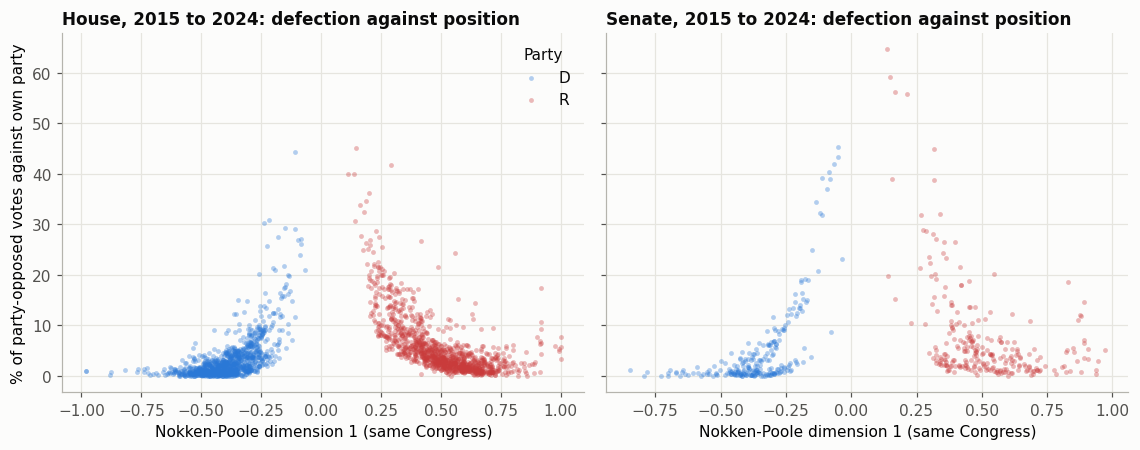

The 10% of members who defect most in each Congress, 2015 to 2024: where they sit within their party


edge           half toward other party  outer half of party
chamber party                                              
House   D                        0.981                0.019
        R                        0.937                0.063
Senate  D                        1.000                0.000
        R                        0.833                0.167

Most frequent defectors in the 117th and 118th Congresses (2021 to 2024):
House


,,,votes,defection_rate,mean_p_gru,np_toward_other,nokken_poole_dim1
bioname,party,state_abbrev,,,,,
"FITZPATRICK, Brian K.",R,PA,1443,0.399,0.373,0.378,0.124
"KATKO, John",R,NY,569,0.337,0.339,0.335,0.161
"KINZINGER, Adam",R,IL,420,0.307,0.285,0.356,0.140
"CHAVEZ-DEREMER, Lori",R,OR,862,0.276,0.201,0.342,0.167
"LAWLER, Michael",R,NY,858,0.263,0.204,0.321,0.188
"PEREZ, Marie Gluesenkamp",D,WA,860,0.260,0.164,0.322,-0.084
"UPTON, Frederick Stephen",R,MI,573,0.260,0.288,0.291,0.205
"KEAN, Thomas",R,NJ,870,0.252,0.199,0.315,0.194
"KILEY, Kevin",R,CA,865,0.212,0.165,0.255,0.254


Senate


,,,votes,defection_rate,mean_p_gru,np_toward_other,nokken_poole_dim1
bioname,party,state_abbrev,,,,,
"COLLINS, Susan Margaret",R,ME,1309,0.619,0.677,0.372,0.144
"MURKOWSKI, Lisa",R,AK,1233,0.561,0.560,0.325,0.190
"GRAHAM, Lindsey O.",R,SC,1212,0.418,0.503,0.198,0.317
"PORTMAN, Robert Jones (Rob)",R,OH,732,0.321,0.420,0.172,0.338
"BLUNT, Roy",R,MO,701,0.281,0.363,0.196,0.314
"TILLIS, Thomas Roland (Thom)",R,NC,1202,0.255,0.252,0.140,0.376
"ROMNEY, Willard Mitt (Mitt)",R,UT,1207,0.250,0.218,0.241,0.275
"ROUNDS, Marion Michael (Mike)",R,SD,1109,0.244,0.267,0.187,0.328
"BURR, Richard M.",R,NC,659,0.234,0.266,0.147,0.363


In [3]:
recent = states[states["congress"].between(114, 118)]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for axis, chamber in zip(axes, ["House", "Senate"]):
    part = recent[recent["chamber"] == chamber]
    for party in ["D", "R"]:
        p = part[part["party"] == party]
        axis.scatter(p["nokken_poole_dim1"], p["defection_rate"] * 100, s=10, color=COLORS[party], alpha=0.35, linewidths=0, label=party)
    axis.set_title(f"{chamber}, 2015 to 2024: defection against position")
    axis.set_xlabel("Nokken-Poole dimension 1 (same Congress)")
axes[0].set_ylabel("% of party-opposed votes against own party")
axes[0].legend(title="Party")
fig.tight_layout()
plt.show()
# Share of defectors who sit on the party's outer edge rather than toward the other party.
recent = recent.assign(edge=np.where(recent["np_toward_other"] < 0, "outer half of party", "half toward other party"))
top = recent.groupby(["chamber", "party", "congress"], group_keys=False).apply(lambda g: g.nlargest(max(1, len(g) // 10), "defection_rate"))
print("The 10% of members who defect most in each Congress, 2015 to 2024: where they sit within their party")
display(pd.crosstab([top["chamber"], top["party"]], top["edge"], normalize="index").round(3))
print("Most frequent defectors in the 117th and 118th Congresses (2021 to 2024):")
for chamber in ["House", "Senate"]:
    part = states[(states["chamber"] == chamber) & states["congress"].isin([117, 118])]
    part = part.groupby(["bioname", "party", "state_abbrev"], observed=True).agg(
        votes=("votes", "sum"), defection_rate=("defection_rate", "mean"), mean_p_gru=("mean_p_gru", "mean"),
        np_toward_other=("np_toward_other", "mean"), nokken_poole_dim1=("nokken_poole_dim1", "mean"))
    print(chamber)
    display(part.sort_values("defection_rate", ascending=False).head(12).round(3))


*Commentary pending: shape.*

## What the hidden state holds

Variance explained by the first three components of the average state: [0.453 0.132 0.108]
Rank correlation of the first component with each measure, pooled over Congresses, within chamber and party:


,House D,House R,Senate D,Senate R
Nokken-Poole dim 1,-0.380,0.237,-0.376,0.413
Nokken-Poole toward other party,-0.210,-0.001,-0.329,-0.259
distance from centre |Nokken-Poole|,0.375,0.237,0.375,0.413
actual defection rate,-0.520,-0.498,-0.710,-0.533
GRU propensity,-0.603,-0.527,-0.745,-0.572


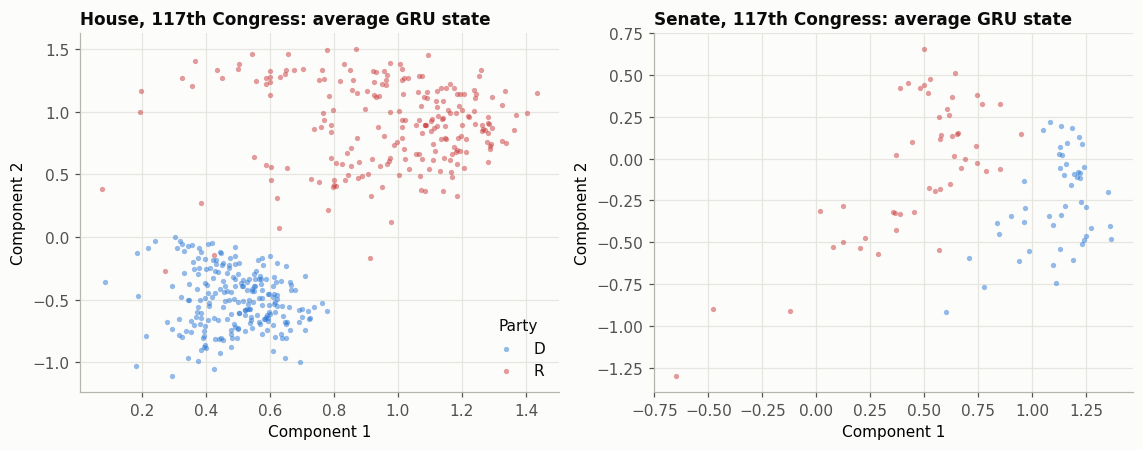

In [4]:
# One trained network gives every member the same state space, so states from different years are comparable
# without alignment, as long as the inputs mean the same thing. That is an assumption, not a test.
pca = PCA(n_components=3).fit(states[hidden])
components = pca.transform(states[hidden])
states["pc1"], states["pc2"] = components[:, 0], components[:, 1]
print("Variance explained by the first three components of the average state:", pca.explained_variance_ratio_.round(3))
checks = {}
for name, column in [("Nokken-Poole dim 1", "nokken_poole_dim1"), ("Nokken-Poole toward other party", "np_toward_other"),
                     ("distance from centre |Nokken-Poole|", "np_extremity"), ("actual defection rate", "defection_rate"), ("GRU propensity", "mean_p_gru")]:
    checks[name] = {f"{chamber} {party}": spearmanr(g["pc1"], g[column], nan_policy="omit").statistic
                    for (chamber, party), g in states.groupby(["chamber", "party"])}
print("Rank correlation of the first component with each measure, pooled over Congresses, within chamber and party:")
display(pd.DataFrame(checks).T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for axis, chamber in zip(axes, ["House", "Senate"]):
    part = states[(states["chamber"] == chamber) & (states["congress"] == 117)]
    for party in ["D", "R"]:
        p = part[part["party"] == party]
        axis.scatter(p["pc1"], p["pc2"], s=12, color=COLORS[party], alpha=0.5, linewidths=0, label=party)
    axis.set_title(f"{chamber}, 117th Congress: average GRU state")
    axis.set_xlabel("Component 1")
    axis.set_ylabel("Component 2")
axes[0].legend(title="Party")
fig.tight_layout()
plt.show()


*Commentary pending: pca.*

## Member trajectories

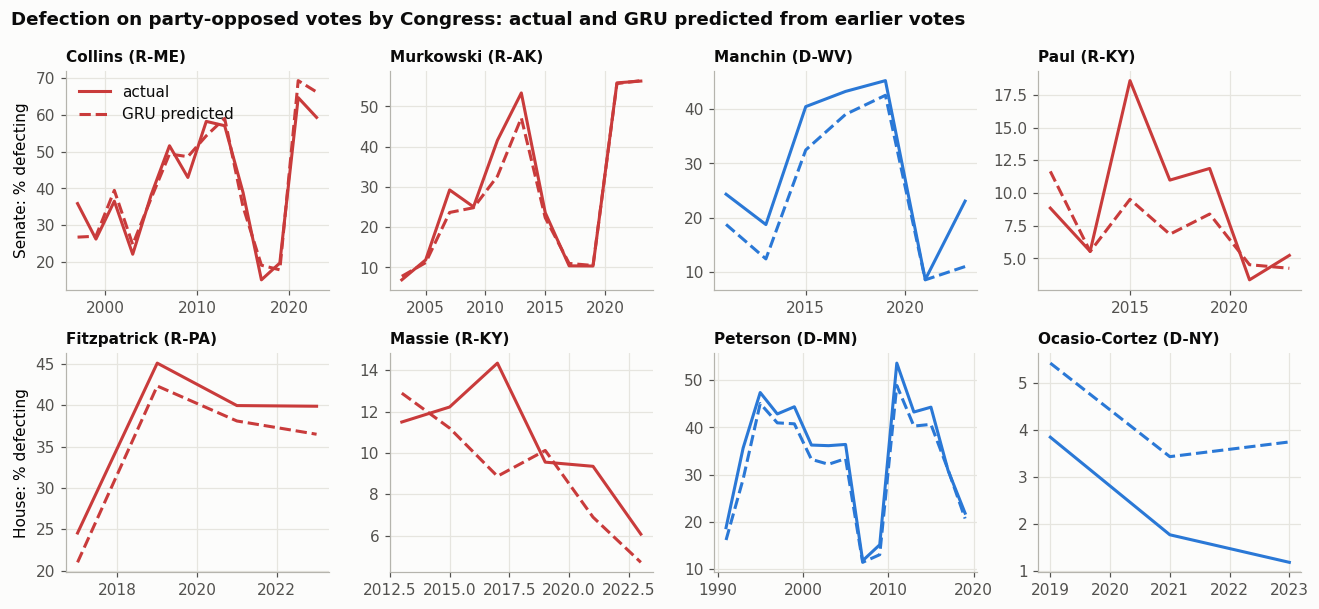

In [5]:
PEOPLE = {"Senate": ["COLLINS, Susan Margaret", "MURKOWSKI, Lisa", "MANCHIN, Joe, III", "PAUL, Rand"],
          "House": ["FITZPATRICK, Brian K.", "MASSIE, Thomas", "PETERSON, Collin Clark", "OCASIO-CORTEZ, Alexandria"]}
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), sharex=False)
for row, (chamber, names) in enumerate(PEOPLE.items()):
    for column, name in enumerate(names):
        axis = axes[row, column]
        person = states[(states["chamber"] == chamber) & (states["bioname"] == name)].sort_values("congress")
        if person.empty:
            axis.set_title(f"{name}: not found")
            continue
        color = COLORS[person["party"].iloc[0]]
        axis.plot(person["year"], person["defection_rate"] * 100, color=color, label="actual")
        axis.plot(person["year"], person["mean_p_gru"] * 100, color=color, linestyle="--", label="GRU predicted")
        axis.set_title(name.split(",")[0].title() + f" ({person['party'].iloc[0]}-{person['state_abbrev'].iloc[0]})", fontsize=10)
        if column == 0:
            axis.set_ylabel(f"{chamber}: % defecting")
axes[0, 0].legend()
fig.suptitle("Defection on party-opposed votes by Congress: actual and GRU predicted from earlier votes", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()


*Commentary pending: trajectories.*

*Commentary pending: summary.*